# 03 香港 AQHI：探索性分析与样本窗口检查

使用最新一次完整的全历史导出。原始数据不修改，不插值、不训练模型。
候选分析范围：源日期从2020年6月1日起，18个站点。该范围是分析选择，不是最终训练划分。

已确认：三个语言版本的2023年8月文件都只包含1日至24日。
保留8月25日至31日缺口；输入或预测区间跨越缺口的样本不得用于训练。
这不等同于监测站停测的证据。

来源：[香港环保署历史AQHI](https://data.gov.hk/sc-data/dataset/hk-epd-airteam-past-record-of-air-quality-health-index-sc)。
按顺序运行；输出图表使用英文以避免中文字体缺失。

In [1]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src' / 'aqhi_data.py').exists(): ROOT = ROOT.parent
BASE = ROOT / 'data' / 'processed' / 'full_history'
candidates = []
for p in sorted(BASE.iterdir()):
    if (p/'summary.json').exists() and (p/'history_all_audited.csv.gz').exists():
        meta = json.loads((p/'summary.json').read_text(encoding='utf-8'))
        if meta['source_month_start'] == '201312' and meta['source_month_end'] == '202606':
            candidates.append(p)
assert candidates, '请先完整运行02全历史Notebook'
SOURCE = candidates[-1]
history = pd.read_csv(SOURCE/'history_all_audited.csv.gz', keep_default_na=False,
    dtype={'source_month': str, 'source_date': str, 'source_hour': str})
history['timestamp'] = pd.to_datetime(history.timestamp, utc=True).dt.tz_convert('Asia/Hong_Kong')
history['aqhi_value'] = pd.to_numeric(history.aqhi_value, errors='coerce')
FLAGS = ['is_missing', 'is_unavailable', 'is_substituted', 'is_10_plus', 'is_invalid']
for col in FLAGS:
    if history[col].dtype != bool:
        assert history[col].astype(str).isin(['True', 'False']).all()
        history[col] = history[col].astype(str).eq('True')
assert not history.duplicated(['station_id', 'timestamp']).any(), '存在重复记录，先处理再分析'
START_DATE = '2020-06-01'
data = history.loc[history.source_date.ge(START_DATE)].copy()
stations = pd.read_csv(SOURCE/'stations_snapshot.csv')
data = data.merge(stations[['station_id', 'station_type']], on='station_id', how='left', validate='many_to_one')
assert data.station_type.notna().all()
assert data.station_id.nunique() == 18
OUT = ROOT/'data'/'processed'/'eda'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True, exist_ok=False)
print('输入：', SOURCE)
print('分析记录数：', len(data), '站点数：', data.station_id.nunique())
print('输出：', OUT)
plt.rcParams.update({'figure.figsize': (12, 5), 'figure.dpi': 110})
def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT/f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

输入： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\full_history\20261110_170756_651230
分析记录数： 956448 站点数： 18
输出： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\eda\20261110_173215_073412


## 1. 缺口登记与质量统计

缺口时间按香港时间记录，含首尾小时；沿用02的24时解析约定。
质量比例的分母是已有记录行数，不含完全缺失的小时行；各标记可能重叠。
`10+` 是有效的上限类别，不是普通缺测，但不能当作精确数值10或11。


,is_missing,is_unavailable,is_substituted,is_10_plus,is_invalid,rows,is_missing_pct,is_unavailable_pct,is_substituted_pct,is_10_plus_pct,is_invalid_pct
station_id,,,,,,,,,,,
Causeway Bay,502,10,1135,10,0,53136,0.94,0.02,2.14,0.02,0.0
Central,501,27,1419,7,0,53136,0.94,0.05,2.67,0.01,0.0
Central/Western,501,8,987,35,0,53136,0.94,0.02,1.86,0.07,0.0
Eastern,501,8,1238,12,0,53136,0.94,0.02,2.33,0.02,0.0
Kwai Chung,501,8,1001,14,0,53136,0.94,0.02,1.88,0.03,0.0
Kwun Tong,501,8,1064,17,0,53136,0.94,0.02,2.00,0.03,0.0
Mong Kok,503,9,1226,9,0,53136,0.95,0.02,2.31,0.02,0.0
North,1442,12,1979,24,0,53136,2.71,0.02,3.72,0.05,0.0
Sha Tin,501,12,1154,3,0,53136,0.94,0.02,2.17,0.01,0.0


,station_id,start_inclusive,end_inclusive,hours,reason,policy
0,Causeway Bay,2023-08-25 01:00:00+08:00,2023-09-01 00:00:00+08:00,168,Absent from downloaded monthly files; cause un...,Keep missing; exclude any input/target window ...
1,Central,2023-08-25 01:00:00+08:00,2023-09-01 00:00:00+08:00,168,Absent from downloaded monthly files; cause un...,Keep missing; exclude any input/target window ...


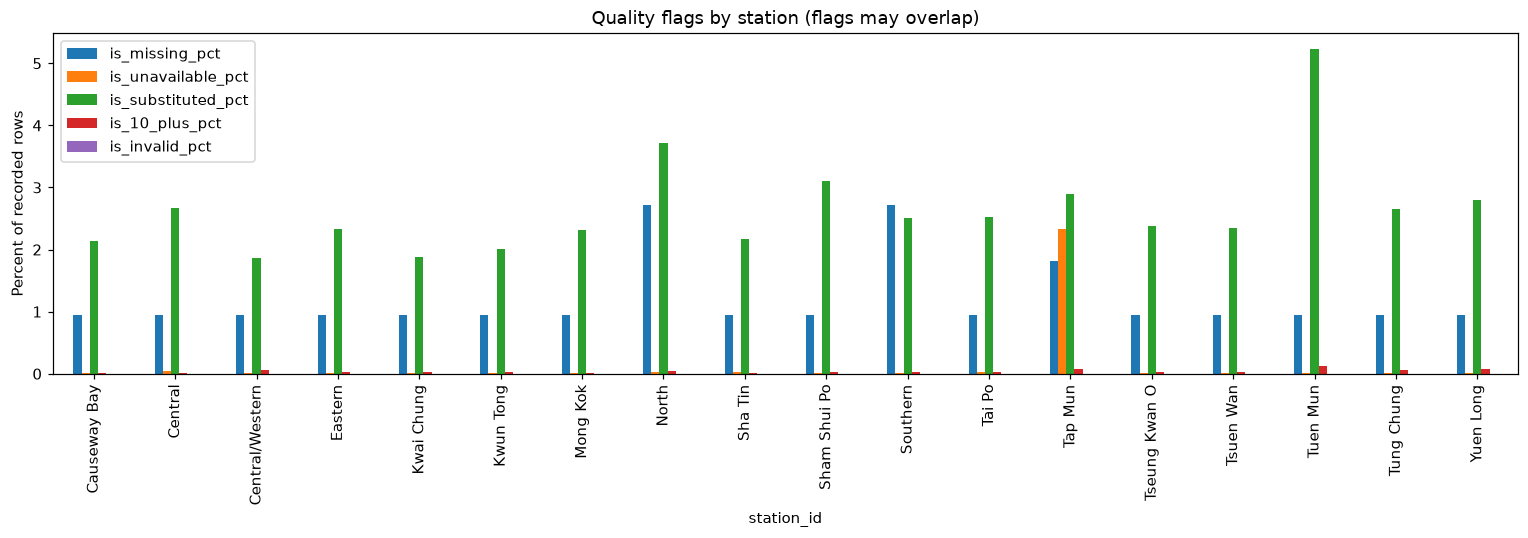

In [2]:
gap_start = pd.Timestamp('2023-08-25 01:00', tz='Asia/Hong_Kong')
gap_end = pd.Timestamp('2023-09-01 00:00', tz='Asia/Hong_Kong')
gap_times = pd.date_range(gap_start, gap_end, freq='h')
assert len(gap_times) == 168
gap_register = pd.DataFrame([{'station_id': s, 'start_inclusive': str(gap_start),
    'end_inclusive': str(gap_end), 'hours': 168, 'reason': 'Absent from downloaded monthly files; cause unconfirmed',
    'policy': 'Keep missing; exclude any input/target window crossing this gap'}
    for s in sorted(data.station_id.unique())])
for s, g in data.groupby('station_id'):
    expected = pd.date_range(g.timestamp.min(), g.timestamp.max(), freq='h')
    absent = expected.difference(pd.DatetimeIndex(g.timestamp))
    assert absent.equals(gap_times), f'{s} 的缺口与登记不一致，请复核'
quality = data.groupby('station_id')[FLAGS].sum()
quality['rows'] = data.groupby('station_id').size()
for f in FLAGS: quality[f+'_pct'] = 100 * quality[f] / quality.rows
display(quality.round(2))
display(gap_register.head(2))
quality[[f+'_pct' for f in FLAGS]].plot.bar(figsize=(14, 5))
plt.ylabel('Percent of recorded rows')
plt.title('Quality flags by station (flags may overlap)')
save_plot('01_quality_flags')

## 2. 时间与站点规律

以下均值仅使用精确数值1–10，包含带星号但有精确数值的记录，排除空白、不可用及10+。
因此这些图是描述性统计，不代表包含10+的总体平均，也不是健康建议。
以源日期的月份分组，避免月末24时被分入下月。


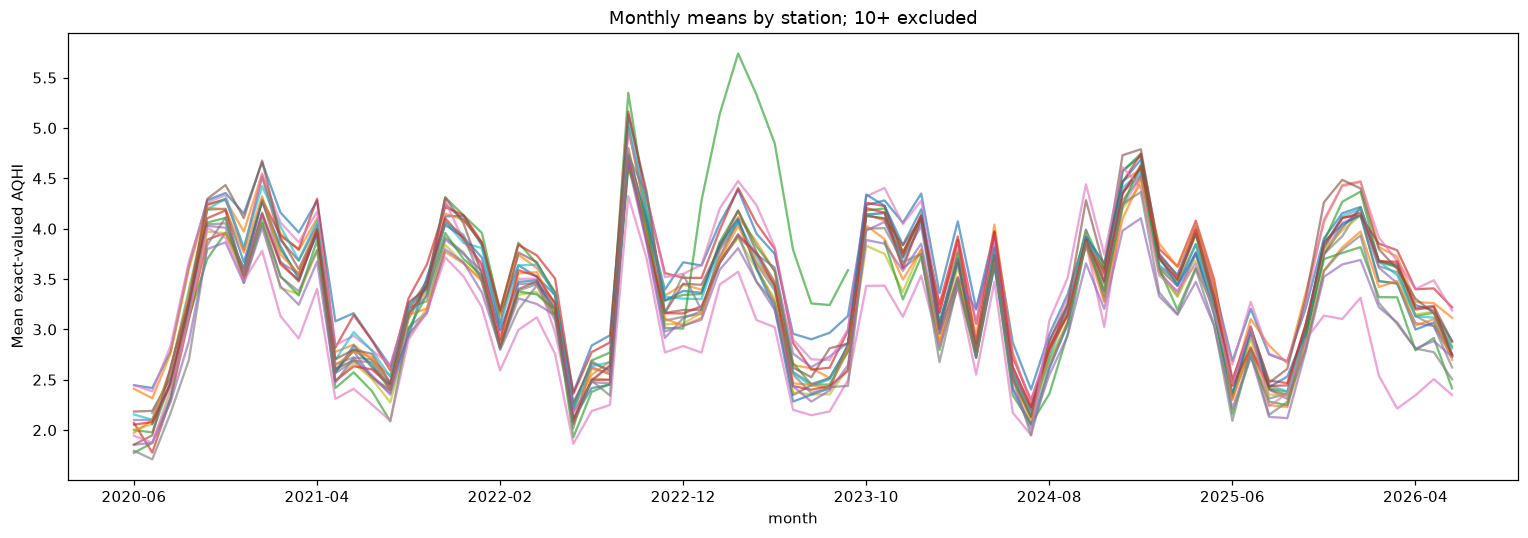

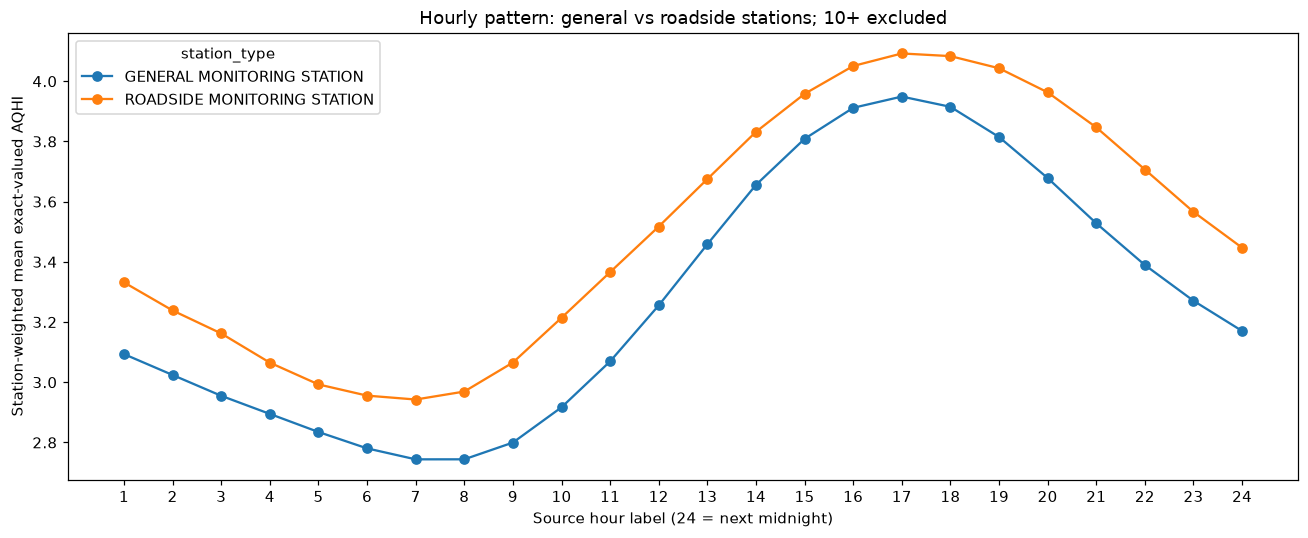

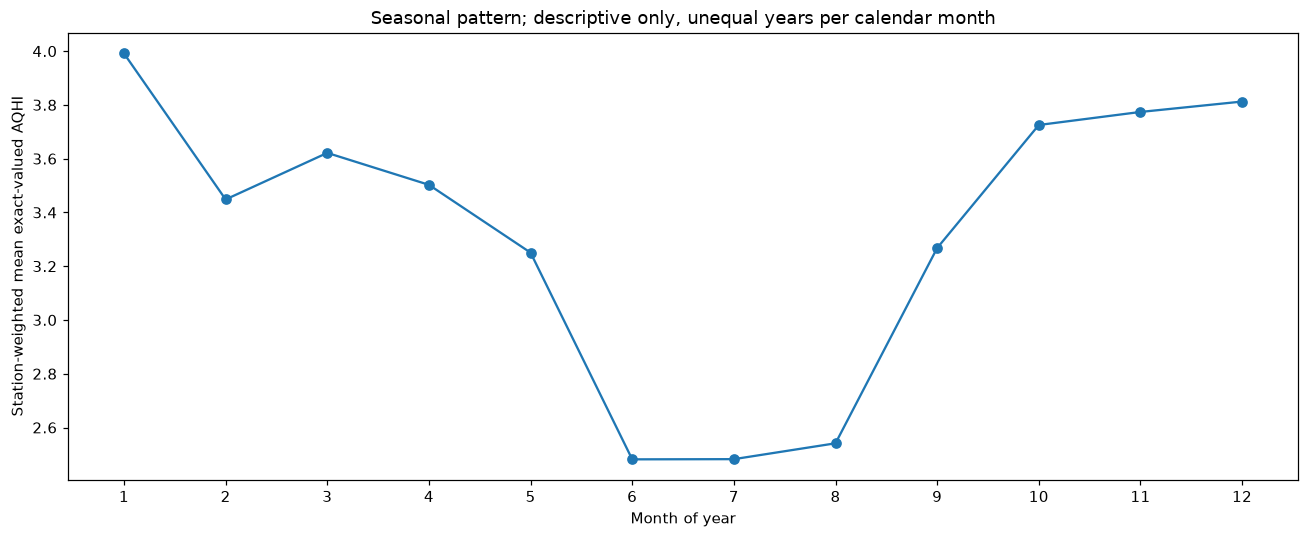

In [3]:
data['month'] = data.source_date.str[:7]
data['hour_label'] = pd.to_numeric(data.source_hour)
exact = data.loc[data.aqhi_value.notna()].copy()
monthly = exact.groupby(['month', 'station_id']).aqhi_value.agg(['mean', 'count']).reset_index()
monthly_mean = monthly.pivot(index='month', columns='station_id', values='mean')
monthly_mean.plot(legend=False, alpha=0.65, figsize=(14, 5))
plt.ylabel('Mean exact-valued AQHI')
plt.title('Monthly means by station; 10+ excluded')
save_plot('02_monthly_station_trends')

# 先在站点内求均值，再对同类型站点等权平均。
station_hour = exact.groupby(['station_type', 'station_id', 'hour_label']).aqhi_value.mean()
hour_pattern = station_hour.groupby(['station_type', 'hour_label']).mean().unstack(0)
hour_pattern.plot(marker='o')
plt.xticks(range(1,25)); plt.xlabel('Source hour label (24 = next midnight)')
plt.ylabel('Station-weighted mean exact-valued AQHI')
plt.title('Hourly pattern: general vs roadside stations; 10+ excluded')
save_plot('03_hourly_patterns')

seasons = exact.assign(month_of_year=exact.source_date.str[5:7].astype(int))
station_season = seasons.groupby(['station_id', 'month_of_year']).aqhi_value.mean()
season_pattern = station_season.groupby('month_of_year').mean()
season_pattern.plot(marker='o')
plt.xticks(range(1,13)); plt.xlabel('Month of year')
plt.ylabel('Station-weighted mean exact-valued AQHI')
plt.title('Seasonal pattern; descriptive only, unequal years per calendar month')
save_plot('04_seasonal_pattern')

## 3. AQHI分布与替代记录敏感性

类别分布保留10+，同时显示未知/不可用记录；不同类型站点先各自计算比例，再等权平均。
比较包含/排除星号的均值只用于检查数据组成的影响，不是因果分析。

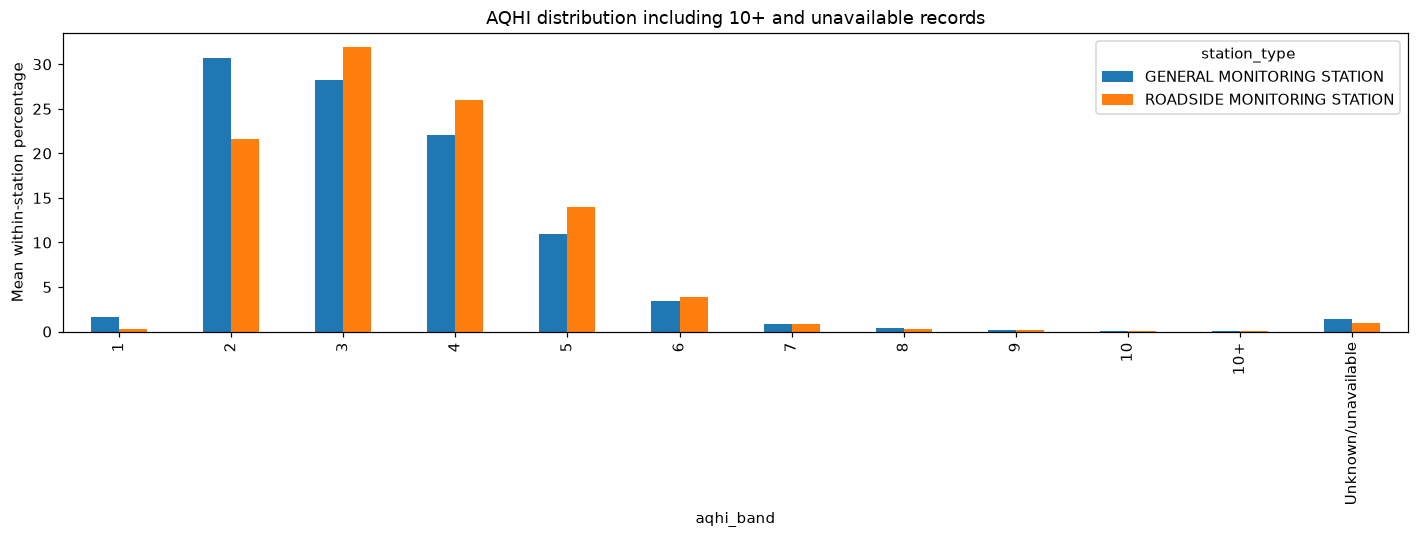

,mean_including_star,count_including_star,mean_without_star,count_without_star,mean_difference
station_id,,,,,
Causeway Bay,3.552,52614,3.551,51480,0.001
Central,3.455,52601,3.455,51200,-0.000
Central/Western,3.373,52592,3.374,51605,-0.002
Eastern,3.473,52615,3.474,51377,-0.001
Kwai Chung,3.274,52613,3.269,51612,0.005
Kwun Tong,3.343,52610,3.340,51546,0.003
Mong Kok,3.504,52615,3.500,51391,0.004
North,3.289,51658,3.292,49679,-0.004
Sha Tin,3.196,52620,3.192,51466,0.004


In [7]:
data['aqhi_band'] = data.aqhi_raw.astype(str).str.replace('*', '', regex=False).str.strip()
labels = [str(i) for i in range(1,11)] + ['10+', 'Unknown/unavailable']
data.loc[~data.aqhi_band.isin(labels[:-1]), 'aqhi_band'] = labels[-1]
band_counts = pd.crosstab([data.station_type, data.station_id], data.aqhi_band).reindex(columns=labels, fill_value=0)
band_pct = band_counts.div(band_counts.sum(axis=1), axis=0)*100
type_distribution = band_pct.groupby(level='station_type').mean()
type_distribution.T.plot.bar(figsize=(13,5))
plt.ylabel('Mean within-station percentage')
plt.title('AQHI distribution including 10+ and unavailable records')
save_plot('05_aqhi_distribution')
sensitivity = exact.groupby('station_id').aqhi_value.agg(mean_including_star='mean', count_including_star='count')
nonstar = exact.loc[~exact.is_substituted].groupby('station_id').aqhi_value.agg(mean_without_star='mean', count_without_star='count')
sensitivity = sensitivity.join(nonstar)
sensitivity['mean_difference'] = sensitivity.mean_including_star - sensitivity.mean_without_star
display(sensitivity.round(3))

## 4. 预测窗口可用性检查（不是训练或测试结果）

候选方案：过去72小时预测未来24小时。窗口按每小时滑动。
分别统计：全部候选窗口、时间记录完整窗口，以及每个值均为精确数值的保守候选窗口。
带星号数值暂时保留；10+窗口被保守数值筛选排除，但这可能低估高风险情形，最终建模前须决定截尾/分类处理。
此处逐站计数，不是18站联合模型的可用窗口数。后续必须另外按时间划分数据，防止训练/验证/测试泄漏。


In [5]:
LOOKBACK, HORIZON = 72, 24
WIDTH = LOOKBACK + HORIZON
window_rows = []
for station, group in data.groupby('station_id'):
    index = pd.date_range(group.timestamp.min(), group.timestamp.max(), freq='h')
    g = group.set_index('timestamp').reindex(index)
    present = pd.Series(index.isin(group.timestamp), index=index)
    continuous = present.astype(int).rolling(WIDTH, min_periods=WIDTH).sum().eq(WIDTH)
    numeric = g.aqhi_value.notna().astype(int).rolling(WIDTH, min_periods=WIDTH).sum().eq(WIDTH)
    touches_gap = pd.Series(index.isin(gap_times), index=index).astype(int).rolling(WIDTH, min_periods=WIDTH).sum().gt(0)
    eligible = continuous & numeric
    assert not (eligible & touches_gap).any()
    window_rows.append({'station_id': station, 'candidate_windows': max(0,len(index)-WIDTH+1),
        'continuous_windows': int(continuous.sum()), 'windows_crossing_known_gap': int(touches_gap.sum()),
        'exact_numeric_windows': int(eligible.sum())})
window_audit = pd.DataFrame(window_rows)
display(window_audit)
# 合成小样本测试：缺一小时后，所有覆盖缺口的窗口必须不可用。
test = pd.Series([True, True, False, True, True, True])
assert test.astype(int).rolling(3).sum().eq(3).tolist() == [False,False,False,False,False,True]
print('窗口连续性测试通过；尚未生成训练样本。')

,station_id,candidate_windows,continuous_windows,windows_crossing_known_gap,exact_numeric_windows
0,Causeway Bay,53209,52946,263,50859
1,Central,53209,52946,263,50941
2,Central/Western,53209,52946,263,50563
3,Eastern,53209,52946,263,50955
4,Kwai Chung,53209,52946,263,50981
5,Kwun Tong,53209,52946,263,50928
6,Mong Kok,53209,52946,263,50955
7,North,53209,52946,263,49808
8,Sha Tin,53209,52946,263,51150
9,Sham Shui Po,53209,52946,263,50957


窗口连续性测试通过；尚未生成训练样本。


## 5. 保存分析结果与处理约定
本次输出使用独立目录，旧文件保持不变。

In [6]:
tables = {'gap_register': gap_register, 'station_quality': quality.reset_index(),
    'monthly_station_stats': monthly, 'hourly_pattern': hour_pattern.reset_index(),
    'seasonal_pattern': season_pattern.rename('mean_exact_aqhi').reset_index(),
    'aqhi_distribution': type_distribution.reset_index(),
    'substitution_sensitivity': sensitivity.reset_index(), 'window_availability': window_audit}
for name, table in tables.items():
    table.to_csv(OUT/f'{name}.csv', index=False, encoding='utf-8-sig')
policy = {'input_directory': str(SOURCE), 'analysis_start_source_date': START_DATE,
    'analysis_rows': len(data), 'stations': int(data.station_id.nunique()),
    'gap_start_inclusive': str(gap_start), 'gap_end_inclusive': str(gap_end),
    'gap_policy': 'No imputation; exclude windows whose input or target spans missing timestamps',
    'lookback_candidate': LOOKBACK, 'horizon_candidate': HORIZON,
    'exact_numeric_means_exclude_10_plus': True, 'substituted_values_retained': True,
    'training_split': 'not yet defined', 'model_trained': False,
    'open_decisions': ['10+ treatment', 'substituted values policy', 'other missing values policy', 'chronological split and scaling on training data only']}
(OUT/'analysis_policy.json').write_text(json.dumps(policy, ensure_ascii=False, indent=2), encoding='utf-8')
print('已保存5张图、8份统计表及分析约定：', OUT)
print('下一步：确定预测目标、10+处理及时间划分，然后建立基准预测。')

已保存5张图、8份统计表及分析约定： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\eda\20261110_173215_073412
下一步：确定预测目标、10+处理及时间划分，然后建立基准预测。
